# Classical models: a live walkthrough (notebook 02)

One seed-0 split, one pipeline from the course slides end to end: dummy baselines,
TF-IDF logistic regression with a threshold picked on validation, BM25, a decision
tree and an MLP, then explanations, error reading and a per-group check. Only
training and validation rows are used here; the test split stays untouched and is
read from saved files in notebook 03.

Run time: about 5 minutes.

In [1]:
import sys, os; os.chdir(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else None; sys.path.insert(0, "."); import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from modules import data_helper as dh
from modules import features as ft
from modules import models as md
from modules import eval_helper as ev
from modules import explain_helper as eh

DATA = "../data/fake_job_postings.csv"

In [2]:
SEED = 0
SPLIT_PATH = "splits/seed0.npz"

dh.seed_everything(SEED)
sns.set_theme(style="whitegrid")

## Setup: the seed-0 split

Load, clean, add features, and reuse the saved seed-0 split (Session 5: split
first, then fit on the training rows only).

In [3]:
df = ft.add_engineered_features(dh.clean(dh.load_raw(DATA)))
if os.path.exists(SPLIT_PATH):
    splits = dh.load_splits(SPLIT_PATH, df)
else:
    splits = dh.make_splits(df, seed=SEED)
    dh.save_splits(SPLIT_PATH, splits, df)
assert not set(splits["train"]) & set(splits["val"]), "train/val row overlap"
train = df.iloc[splits["train"]]
val = df.iloc[splits["val"]]
y_train = train["fraudulent"].to_numpy()
y_val = val["fraudulent"].to_numpy()

In [4]:
y_all = df["fraudulent"].to_numpy()
for name in ("train", "val", "test"):
    idx = splits[name]
    print(f"{name:5s}: {len(idx):6d} rows, {int(y_all[idx].sum()):4d} fraud ({y_all[idx].mean():.1%})")
print("test rows are listed for completeness; this notebook never scores them")

train:  10559 rows,  514 fraud (4.9%)
val  :   3520 rows,  171 fraud (4.9%)
test :   3520 rows,  171 fraud (4.9%)
test rows are listed for completeness; this notebook never scores them


## One helper for every model

The same three steps each time: fit on train, pick the decision threshold on
validation (never on test), then report train and validation side by side so the
generalisation gap is visible (Session 6). `ev.compare_table` names its second split
"test"; we pass validation metrics there and rename the columns below, so the test
rows are never touched.

In [5]:
fitted, thresholds, scores, results = {}, {}, {}, {}

def report(name, model):
    """Score a fitted model; the threshold is picked on validation only."""
    s_val = ev.score_of(model, val)
    thr = ev.pick_threshold(y_val, s_val)
    results[name] = {"train": ev.evaluate(y_train, ev.score_of(model, train), thr),
                     "test": ev.evaluate(y_val, s_val, thr)}
    fitted[name], thresholds[name], scores[name] = model, thr, s_val
    out = pd.DataFrame(results[name]).T.rename(index={"test": "val"})  # "test" slot holds validation
    out = out[["pr_auc", "roc_auc", "f1", "precision", "recall"]]
    out.insert(0, "model", name)
    return out

## The dummy baseline (Sessions 6/7)

Every model has to beat the dumb references first: `dummy_majority` always predicts
the majority class; `dummy_stratified` guesses the class at the training rates.

In [6]:
frames = [report(name, est.fit(train, y_train))
          for name, est in md.get_baselines(SEED).items()]
pd.concat(frames)

,model,pr_auc,roc_auc,f1,precision,recall
train,dummy_majority,0.048679,0.500000,0.092838,0.048679,1.0
val,dummy_majority,0.048580,0.500000,0.092658,0.048580,1.0
train,dummy_stratified,0.048919,0.502372,0.092838,0.048679,1.0
val,dummy_stratified,0.048471,0.498783,0.092658,0.048580,1.0


## Logistic regression on TF-IDF + engineered features

`modules/models.py` builds one Pipeline: TF-IDF over the joined text, one-hot and
ordinal encoded metadata, scaled numeric flags, then a `class_weight="balanced"`
logistic regression.

In [7]:
report("logreg", md.get_models(SEED)["logreg"].fit(train, y_train))

,model,pr_auc,roc_auc,f1,precision,recall
train,logreg,0.979949,0.999025,0.915323,0.949791,0.883268
val,logreg,0.824794,0.980151,0.773163,0.852113,0.707602


### Confusion matrix on validation

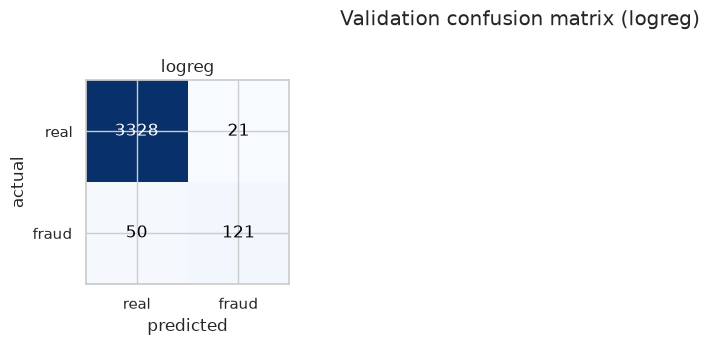

In [8]:
m = results["logreg"]["test"]  # validation metrics (see the helper above)
cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
ev.plot_confusions({"logreg": cm}, ["real", "fraud"],
                   title="Validation confusion matrix (logreg)")
plt.show()

Reading: rows are the actual class, columns the predicted one; the diagonal holds
the correct calls.

### The threshold trade-off

Session 6: with an imbalanced target there is no free lunch between precision and
recall; the threshold is a business decision, and we pick it on validation.

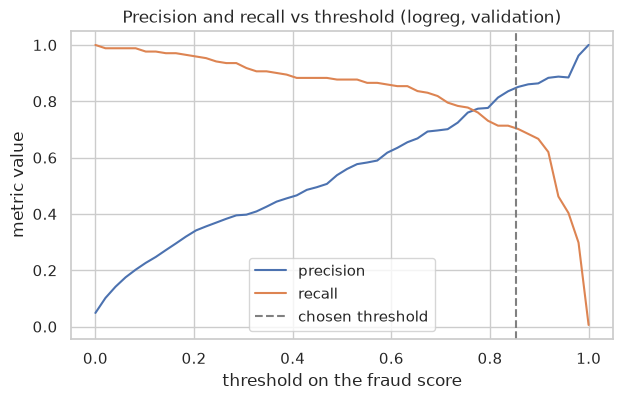

In [9]:
sw = ev.sweep_thresholds(y_val, scores["logreg"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sw["threshold"], sw["precision"], label="precision")
ax.plot(sw["threshold"], sw["recall"], label="recall")
ax.axvline(thresholds["logreg"], color="grey", linestyle="--", label="chosen threshold")
ax.set_xlabel("threshold on the fraud score")
ax.set_ylabel("metric value")
ax.set_title("Precision and recall vs threshold (logreg, validation)")
ax.legend()
plt.show()

Reading: the dashed line is the threshold picked on validation; moving it right can
only shrink the set of flagged ads.

## BM25 instead of TF-IDF

BM25 is the ranking function behind classic search engines. It differs from TF-IDF
in two ways: repeating a word has diminishing returns (saturating term frequency),
and long ads are discounted relative to the average ad length (length normalisation).
The vocabulary and everything else in the pipeline are identical, so any difference
in the numbers comes from the weighting alone.

In [10]:
report("logreg_bm25", md.get_models(SEED)["logreg_bm25"].fit(train, y_train))

,model,pr_auc,roc_auc,f1,precision,recall
train,logreg_bm25,0.982686,0.999157,0.935211,0.903811,0.968872
val,logreg_bm25,0.827157,0.980638,0.778761,0.785714,0.771930


## Decision tree

Easy to read, prone to overfitting on sparse text. `tree_rules` prints the top
levels of the fitted tree; `top_tree_features` lists the features it leans on.

In [11]:
report("tree", md.get_models(SEED)["tree"].fit(train, y_train))

,model,pr_auc,roc_auc,f1,precision,recall
train,tree,0.981589,0.999052,0.907084,0.860384,0.959144
val,tree,0.504271,0.886966,0.668394,0.600000,0.754386


In [12]:
print(eh.tree_rules(fitted["tree"], max_depth=3))

|--- binary__missing_company_profile <= 0.50
|   |--- text__encouraged <= 0.04
|   |   |--- text__process provide <= 0.05
|   |   |   |--- text__high school <= 0.05
|   |   |   |   |--- truncated branch of depth 12
|   |   |   |--- text__high school >  0.05
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- text__process provide >  0.05
|   |   |   |--- text__professional <= 0.03
|   |   |   |   |--- class: 0
|   |   |   |--- text__professional >  0.03
|   |   |   |   |--- truncated branch of depth 2
|   |--- text__encouraged >  0.04
|   |   |--- text__growing <= 0.02
|   |   |   |--- text__looking <= 0.04
|   |   |   |   |--- truncated branch of depth 8
|   |   |   |--- text__looking >  0.04
|   |   |   |   |--- class: 0
|   |   |--- text__growing >  0.02
|   |   |   |--- class: 0
|--- binary__missing_company_profile >  0.50
|   |--- ordinal__required_experience <= 1.62
|   |   |--- binary__has_company_logo <= 0.50
|   |   |   |--- text__web <= 0.05
|   |   |   |   |--- tru

In [13]:
eh.top_tree_features(fitted["tree"], k=10)

,term,importance
0,binary__missing_company_profile,0.293195
1,text__encouraged,0.144615
2,text__process provide,0.058810
3,text__high school,0.045802
4,ordinal__required_experience,0.039196
5,text__income,0.035713
6,text__real estate,0.024856
7,text__calls,0.019856
8,binary__has_company_logo,0.019425
9,text__telecommunication,0.016576


## MLP on the same features

A small sklearn neural network. It has no `class_weight`, so we rely on the ranking
of its scores plus the threshold picked on validation (Session 5).

In [14]:
report("mlp", md.get_models(SEED)["mlp"].fit(train, y_train))

,model,pr_auc,roc_auc,f1,precision,recall
train,mlp,0.993849,0.998611,0.980431,0.986220,0.974708
val,mlp,0.899189,0.986176,0.856269,0.897436,0.818713


## All models side by side

Train versus validation PR-AUC per model; the gap column is the generalisation gap.
This is validation, not test: `run_classical.py` scores the test split once and
notebook 03 reads it.

In [15]:
table = ev.compare_table(results).rename(columns=lambda c: c.replace("test_", "val_"))
table.sort_values("val_pr_auc", ascending=False)

,model,train_pr_auc,val_pr_auc,train_f1,val_f1,train_recall,val_recall,train_precision,val_precision,gap
5,mlp,0.993849,0.899189,0.980431,0.856269,0.974708,0.818713,0.986220,0.897436,0.094660
3,logreg_bm25,0.982686,0.827157,0.935211,0.778761,0.968872,0.771930,0.903811,0.785714,0.155528
2,logreg,0.979949,0.824794,0.915323,0.773163,0.883268,0.707602,0.949791,0.852113,0.155154
4,tree,0.981589,0.504271,0.907084,0.668394,0.959144,0.754386,0.860384,0.600000,0.477317
0,dummy_majority,0.048679,0.048580,0.092838,0.092658,1.000000,1.000000,0.048679,0.048580,0.000099
1,dummy_stratified,0.048919,0.048471,0.092838,0.092658,1.000000,1.000000,0.048679,0.048580,0.000448


## Hyper-parameter tuning (switched off)

The full random search over all models and five seeds lives in `run_classical.py`:
grouped cross-validation on the training rows only, scoring PR-AUC (Session 7). The
flag below runs a tiny live version (`n_iter=3, cv=3`); keep it False during the
demo.

In [16]:
RUN_TUNING = False  # flip to True to run a small random search live (slow)

if RUN_TUNING:
    # Grouped CV on the training rows so duplicate descriptions cannot leak across folds.
    search = md.tune(md.get_models(SEED)["logreg"], md.PARAM_GRIDS["logreg"],
                     train, y_train, train["group"].to_numpy(),
                     n_iter=3, cv=3, seed=SEED)
    print("best params:", search.best_params_)
    print("CV PR-AUC:", round(float(search.best_score_), 3))

## Which words drive the logreg?

Session 6: read the model. `top_linear_terms` maps the coefficients back to feature
names recovered from the fitted ColumnTransformer.

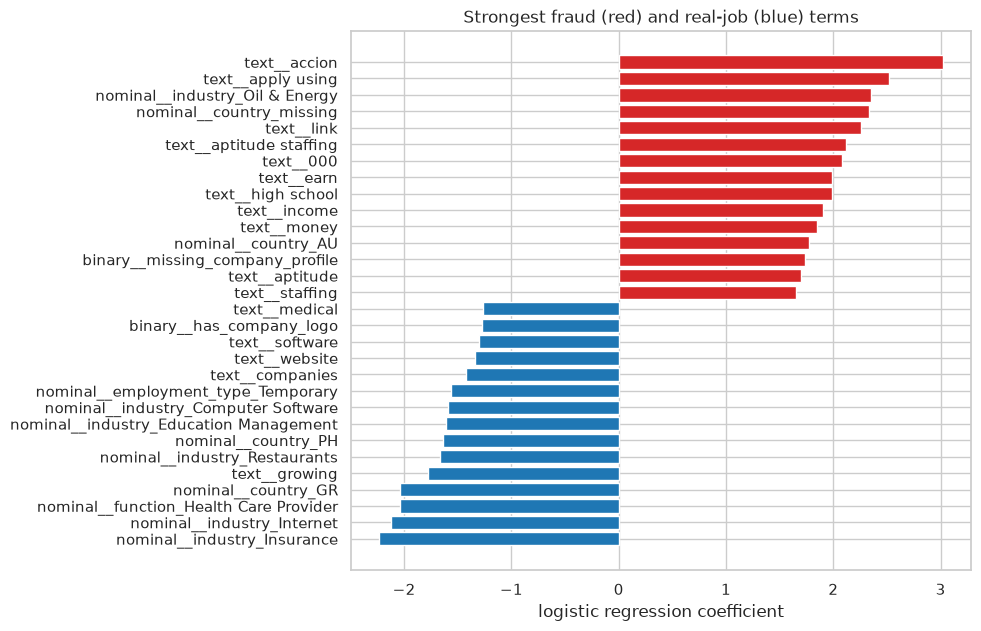

In [17]:
terms = eh.top_linear_terms(fitted["logreg"], k=15).sort_values("coef")
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(terms["term"], terms["coef"],
        color=np.where(terms["coef"] > 0, "tab:red", "tab:blue"))
ax.set_xlabel("logistic regression coefficient")
ax.set_title("Strongest fraud (red) and real-job (blue) terms")
plt.show()

Reading: red bars push an ad towards fraud and blue bars towards real; bar length is
the coefficient, not the importance of a whole input column.

## Which columns matter? Permutation importance

Shuffle one raw input column at a time and see how much validation PR-AUC drops
(Session 6). We use a 1000-row validation sample and a single repeat to keep it
quick.

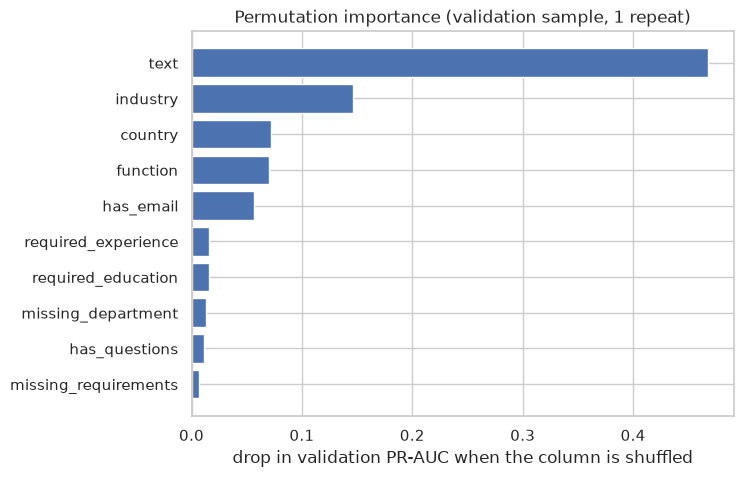

In [18]:
val_sample = val.sample(min(1000, len(val)), random_state=SEED)
perm = eh.permutation_table(fitted["logreg"], val_sample,
                            val_sample["fraudulent"].to_numpy(),
                            n_repeats=1, seed=SEED)
top = perm.head(10).iloc[::-1]  # reversed so the biggest bar lands on top
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top["col"], top["importance_mean"])
ax.set_xlabel("drop in validation PR-AUC when the column is shuffled")
ax.set_title("Permutation importance (validation sample, 1 repeat)")
plt.show()

Reading: the longer the bar, the more the model leaned on that single input column;
near-zero bars mean the column was barely used.

## Read the errors (Session 6)

The five most confident false positives (flagged, but real) and false negatives
(not flagged, but fraud) of the logreg on validation.

In [19]:
errors = eh.show_errors(val, y_val, scores["logreg"], thresholds["logreg"], k=5)
for _, e in errors.iterrows():
    print(f"[{e['error_type']}] score={e['score']:.3f}  title: {e['title']}")
    print(e["description"], "\n")

[false_positive] score=0.990  title: Customer Service 
Our client is seeking an Customer Service with 1 plus years of experience.The ideal candidate must have-1 plus years of experience in the support role-Calendar, scheduling, correspondence, phones-Conf 

[false_positive] score=0.988  title: Human Resources Administrator
JOB DESCRIPTIONThe Human Resources Administrator manages the day-to-day operations of the Human Resource office. The HR Administrator manages the administration of the human resources policies, proced 

[false_positive] score=0.977  title: Entry Level Controller: FT & PT
Are you looking to advance your bookkeeping career with a company that is growing at an exponential rate? Are you a pro with QuickBooks? Are you ready to step up to an Entry Level Controller or a Full 

[false_positive] score=0.977  title: Tankage
A company in oil &amp; gas that has grown into one of Malaysia’s leading integrated specialist technical services providers to the oil, gas and petrochemic

## Per-group check: employment type

Session 6: a model can look fine on average and still fail one group. Recall and
precision by employment type at the logreg's validation threshold.

In [20]:
pred_val = (scores["logreg"] >= thresholds["logreg"]).astype(int)
ev.group_breakdown(y_val, pred_val, val["employment_type"])

,group,count,positives,recall,precision
0,Contract,254,9,0.222222,0.400000
1,Full-time,2274,93,0.752688,0.864198
2,Other,38,0,NaN,0.000000
3,Part-time,151,14,0.785714,0.785714
4,Temporary,65,1,1.000000,1.000000
5,NaN,738,54,0.685185,0.925000


Reading: rows with few ads have noisy recall and precision; the count column says
how much to trust each row.

## Where to next

`run_classical.py` repeats this pipeline for all models with proper tuning over
five split seeds and saves one JSON + NPZ pair per (model, seed) into
`outputs/classical/`. Notebook 03 reads those files and reports the honest test
numbers.